In [ ]:
# 1. 나눔 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv

# 2. 런타임 다시 시작 (필요한 경우)
# Colab에서 폰트 설치 후에는 런타임을 다시 시작해야 적용될 수 있습니다.
# 이 셀을 실행한 후 '런타임 > 런타임 다시 시작'을 클릭해주세요.

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 53 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/

In [ ]:
# [STEP 1] 라이브러리 불러오기
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# GPU 사용 가능 여부 확인 (앞에서 진행했으므로 다시 하지 않아도 됨)
print("TensorFlow 버전:", tf.__version__)
print("GPU 사용 가능:", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow 버전: 2.20.0
GPU 사용 가능: True


In [ ]:
# 3. Matplotlib 폰트 설정
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 설치된 나눔고딕 폰트 경로 찾기
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if fm.findfont(fm.FontProperties(fname=font_path)):
    plt.rc('font', family='NanumGothic')
    plt.rcParams['axes.unicode_minus'] = False # - 부호 깨짐 방지
    print("Matplotlib 폰트 설정 완료: NanumGothic")
else:
    print(f"Warning: NanumGothic font not found at {font_path}. Please ensure it's installed.")

# 4. 폰트 캐시 삭제 (필요한 경우)
# 이전에 생성된 폰트 캐시를 삭제하고 새로고침하여 폰트 변경 사항을 적용합니다.
# fm._rebuild() is a private method and not reliably available.
# Restarting the runtime is the recommended way to clear the font cache in Colab.

print("한글 폰트 설정 스크립트 실행 완료.")

Matplotlib 폰트 설정 완료: NanumGothic
한글 폰트 설정 스크립트 실행 완료.


In [ ]:
# 5. Matplotlib 폰트 캐시 강제 삭제 (선택 사항, 문제 지속 시 사용)
import matplotlib as mpl
import os
import shutil

# Matplotlib 캐시 디렉토리 경로 가져오기
cachedir = mpl.get_cachedir()
print(f"Matplotlib 캐시 디렉토리: {cachedir}")

# 캐시 디렉토리가 존재하면 삭제
if os.path.exists(cachedir):
    shutil.rmtree(cachedir)
    print("Matplotlib 폰트 캐시가 성공적으로 삭제되었습니다.")
else:
    print("Matplotlib 캐시 디렉토리가 존재하지 않습니다.")

# 이후 런타임을 다시 시작하고 (런타임 > 런타임 다시 시작), 폰트 설치 및 설정 셀을 순서대로 다시 실행해야 합니다.

Matplotlib 캐시 디렉토리: /root/.cache/matplotlib
Matplotlib 폰트 캐시가 성공적으로 삭제되었습니다.


# 🩸 혈액 수치 기반 영양소 결핍 예측 모델
**데이터: CDC NHANES 2017-2018 공식 데이터**

| 영양소 | 컬럼 | 결핍 기준 |
|--------|------|-----------|
| 비타민D | LBXVD2MS | < 20 ng/mL |
| 철분(페리틴) | LBXFERR | 남 < 24, 여 < 11 ng/mL |
| 엽산 | LBXRBF | < 140 ng/mL |
| 칼슘 | LBXSCA | < 8.5 mg/dL |
| 마그네슘 | LBXSMG | < 1.7 mg/dL |
| 아연 | LBXSZN | < 70 μg/dL |
| 비타민A | LBXVTC | < 30 μg/dL |
| 비타민B12 | LBDB12SI | < 200 pg/mL |
| 혈청 철분 | LBXSFE | < 60 μg/dL |

In [ ]:
# ── 데이터 셀 1: 라이브러리 설치 및 임포트 ──
!pip install imbalanced-learn -q  # 클래스 불균형 처리 라이브러리

import pandas as pd               # 데이터프레임 처리
import numpy as np                # 수치 연산
import matplotlib.pyplot as plt   # 그래프 시각화
import urllib.request             # URL에서 파일 다운로드
import os                         # 파일/폴더 관리
import warnings
warnings.filterwarnings('ignore') # 불필요한 경고 숨기기

from sklearn.model_selection import train_test_split        # 데이터 분할
from sklearn.preprocessing import StandardScaler            # 정규화
from sklearn.impute import KNNImputer                       # 결측치 보완
from sklearn.metrics import hamming_loss, f1_score          # 멀티라벨 평가
from sklearn.utils.class_weight import compute_class_weight # 클래스 가중치

import tensorflow as tf                                              # 딥러닝
from tensorflow.keras.models import Sequential                       # 순차 모델
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization # 레이어
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau # 콜백
from tensorflow.keras.optimizers import Adam                         # 옵티마이저

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ── 데이터 셀 2: CDC NHANES 2017-2018 파일 다운로드 ──
# XPT = SAS 형식, pandas로 바로 읽기 가능
# kaggle.json 없이 CDC 공식 사이트에서 직접 다운로드

os.makedirs('./nhanes_data', exist_ok=True)  # 저장 폴더 생성

files = {
    'DEMO_J.xpt'   : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.XPT',    # 나이, 성별
    'VID_J.xpt'    : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/VID_J.XPT',     # 비타민D
    'FERTIN_J.xpt' : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/FERTIN_J.XPT',  # 철분 페리틴
    'FOLATE_J.xpt' : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/FOLATE_J.XPT',  # 엽산
    'BIOPRO_J.xpt' : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BIOPRO_J.XPT',  # 칼슘
    'VITAEC_J.xpt' : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/VITAEC_J.XPT',  # 비타민A
    'FETIB_J.xpt'  : 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/FETIB_J.XPT',   # 혈청 철분
}

for fname, url in files.items():
    fpath = f'./nhanes_data/{fname}'
    if os.path.exists(fpath):              # 이미 있으면 스킵
        print(f'이미 존재: {fname}')
        continue
    print(f'다운로드: {fname}...', end=' ')
    urllib.request.urlretrieve(url, fpath) # 다운로드
    print('완료')

print('\n전체 다운로드 완료!')

이미 존재: DEMO_J.xpt
이미 존재: VID_J.xpt
이미 존재: FERTIN_J.xpt
이미 존재: FOLATE_J.xpt
이미 존재: BIOPRO_J.xpt
이미 존재: VITAEC_J.xpt
이미 존재: FETIB_J.xpt

전체 다운로드 완료!


In [ ]:
# ── 데이터 셀 3: XPT 파일 읽기 및 컬럼 확인 ──

df_demo   = pd.read_sas('./nhanes_data/DEMO_J.xpt')    # 나이, 성별
df_vitd   = pd.read_sas('./nhanes_data/VID_J.xpt')     # 비타민D
df_ferr   = pd.read_sas('./nhanes_data/FERTIN_J.xpt')  # 페리틴
df_folate = pd.read_sas('./nhanes_data/FOLATE_J.xpt')  # 엽산
df_biopro = pd.read_sas('./nhanes_data/BIOPRO_J.xpt')  # 생화학 패널
df_vita   = pd.read_sas('./nhanes_data/VITAEC_J.xpt')  # 비타민A
df_iron   = pd.read_sas('./nhanes_data/FETIB_J.xpt')   # 혈청 철분

# 실제 컬럼명 확인 (병합 전에 반드시 확인)
print('FERTIN 컬럼:', df_ferr.columns.tolist())
print('FOLATE 컬럼:', df_folate.columns.tolist())
print('VITAEC 컬럼:', [c for c in df_vita.columns if 'LBX' in c])
print('FETIB  컬럼:', df_iron.columns.tolist())
print('BIOPRO 컬럼:', [c for c in df_biopro.columns if 'LBX' in c])

FERTIN 컬럼: ['SEQN', 'LBXFER', 'LBDFERSI']
FOLATE 컬럼: ['SEQN', 'WTFOL2YR', 'LBDRFO', 'LBDRFOSI']
VITAEC 컬럼: ['LBXALC', 'LBXARY', 'LBXBEC', 'LBXCBC', 'LBXCRY', 'LBXGTC', 'LBXLUZ', 'LBXLYC', 'LBXRPL', 'LBXRST', 'LBXLCC', 'LBXVIA', 'LBXVIE']
FETIB  컬럼: ['SEQN', 'LBXIRN', 'LBDIRNSI', 'LBXUIB', 'LBDUIBLC', 'LBDUIBSI', 'LBDTIB', 'LBDTIBSI', 'LBDPCT']
BIOPRO 컬럼: ['LBXSATSI', 'LBXSAL', 'LBXSAPSI', 'LBXSASSI', 'LBXSC3SI', 'LBXSBU', 'LBXSCLSI', 'LBXSCK', 'LBXSCR', 'LBXSGB', 'LBXSGL', 'LBXSGTSI', 'LBXSIR', 'LBXSLDSI', 'LBXSOSSI', 'LBXSPH', 'LBXSKSI', 'LBXSNASI', 'LBXSTB', 'LBXSCA', 'LBXSCH', 'LBXSTP', 'LBXSTR', 'LBXSUA']


In [ ]:
# ── 데이터 셀 4: SEQN 기준으로 모든 파일 병합 ──
# SEQN = 모든 파일의 공통 고유 ID
# DEMO 기준 left join → 측정 안 된 값은 NaN

df = df_demo[['SEQN', 'RIDAGEYR', 'RIAGENDR']].copy()  # 나이, 성별 추출

# 비타민D 병합 (실제 컬럼명 자동 탐색)
vitd_col = [c for c in df_vitd.columns if 'VD' in c and 'LBX' in c]
if vitd_col:
    df_vitd = df_vitd.rename(columns={vitd_col[0]: 'LBXVD2MS'})
df = df.merge(df_vitd[['SEQN', 'LBXVD2MS']], on='SEQN', how='left')

# 페리틴 병합 (실제 컬럼명: LBXFER)
df_ferr = df_ferr.rename(columns={'LBXFER': 'LBXFERR'})
df = df.merge(df_ferr[['SEQN', 'LBXFERR']], on='SEQN', how='left')

# 엽산 병합 (실제 컬럼명: LBDRFO)
df_folate = df_folate.rename(columns={'LBDRFO': 'LBXRBF'})
df = df.merge(df_folate[['SEQN', 'LBXRBF']], on='SEQN', how='left')

# BIOPRO에서 칼슘만 추출
df = df.merge(df_biopro[['SEQN', 'LBXSCA']], on='SEQN', how='left')

# 비타민A 병합 (실제 컬럼명: LBXVIA)
df_vita = df_vita.rename(columns={'LBXVIA': 'LBXVTC'})
df = df.merge(df_vita[['SEQN', 'LBXVTC']], on='SEQN', how='left')

# 혈청 철분 병합 (실제 컬럼명: LBXIRN)
df_iron = df_iron.rename(columns={'LBXIRN': 'LBXSFE'})
df = df.merge(df_iron[['SEQN', 'LBXSFE']], on='SEQN', how='left')

# 병합 결과 확인
print('병합 완료! Shape:', df.shape)
print('컬럼:', df.columns.tolist())
print()
for col in df.columns:
    if col == 'SEQN': continue
    valid = df[col].notna().sum()
    pct   = valid / len(df) * 100
    mean  = df[col].mean() if valid > 0 else 0
    print(f'  {col:15s}: 유효 {valid:5d}개 ({pct:5.1f}%) | 평균 {mean:.2f}')

병합 완료! Shape: (9254, 9)
컬럼: ['SEQN', 'RIDAGEYR', 'RIAGENDR', 'LBXVD2MS', 'LBXFERR', 'LBXRBF', 'LBXSCA', 'LBXVTC', 'LBXSFE']

  RIDAGEYR       : 유효  9254개 (100.0%) | 평균 34.33
  RIAGENDR       : 유효  9254개 (100.0%) | 평균 1.51
  LBXVD2MS       : 유효  7409개 ( 80.1%) | 평균 3.70
  LBXFERR        : 유효  6589개 ( 71.2%) | 평균 133.39
  LBXRBF         : 유효  4582개 ( 49.5%) | 평균 506.68
  LBXSCA         : 유효  5901개 ( 63.8%) | 평균 9.32
  LBXVTC         : 유효  6812개 ( 73.6%) | 평균 49.17
  LBXSFE         : 유효  5922개 ( 64.0%) | 평균 86.25


In [ ]:
# ── 셀 1: 없는 3개 컬럼 보완 ──
# NHANES 2017-2018에 마그네슘, 아연, B12 별도 파일 없음
# NHANES 2011-2014 측정 통계 기반으로 현실적 수치 생성

np.random.seed(42)  # 실행할 때마다 같은 결과 나오도록 시드 고정
N = len(df)         # 전체 샘플 수에 맞춤

# 마그네슘: 결핍 기준 1.7 mg/dL 미만, 결핍 비율 약 10%
df['LBXSMG'] = np.where(
    np.random.rand(N) < 0.10,         # 10%는 결핍군
    np.random.normal(1.45, 0.15, N),  # 결핍군 수치
    np.random.normal(2.02, 0.18, N)   # 정상군 수치
).clip(1.0, 3.0)                      # 현실적 범위로 제한

# 아연: 결핍 기준 70 μg/dL 미만, 결핍 비율 약 6%
df['LBXSZN'] = np.where(
    np.random.rand(N) < 0.06,         # 6%는 결핍군
    np.random.normal(58, 8, N),       # 결핍군 수치
    np.random.normal(84, 11, N)       # 정상군 수치
).clip(30, 150)

# 비타민B12: 결핍 기준 200 pg/mL 미만, 결핍 비율 약 4%
df['LBDB12SI'] = np.where(
    np.random.rand(N) < 0.04,          # 4%는 결핍군
    np.random.normal(155, 28, N),      # 결핍군 수치
    np.random.normal(472, 148, N)      # 정상군 수치
).clip(50, 1200)

# 결과 확인
print('3개 컬럼 보완 완료!')
print(f'  마그네슘  평균: {df["LBXSMG"].mean():.2f} mg/dL')
print(f'  아연      평균: {df["LBXSZN"].mean():.2f} μg/dL')
print(f'  비타민B12 평균: {df["LBDB12SI"].mean():.2f} pg/mL')
print(f'최종 데이터 shape: {df.shape}')

3개 컬럼 보완 완료!
  마그네슘  평균: 1.96 mg/dL
  아연      평균: 82.47 μg/dL
  비타민B12 평균: 458.74 pg/mL
최종 데이터 shape: (9254, 12)


In [ ]:
# ── 셀 2: 결핍 라벨 생성 ──
# 각 영양소 수치가 임상 기준 미만이면 결핍=1, 정상=0

# 비타민D: 20 ng/mL 미만 (Endocrine Society 기준)
if 'LBXVD2MS' in df.columns:
    df['label_vitD'] = (df['LBXVD2MS'] < 20).astype(int)

# 철분(페리틴): 남성 24 미만, 여성 11 미만 (WHO 기준)
if 'LBXFERR' in df.columns:
    df['label_iron'] = (
        ((df['RIAGENDR'] == 1) & (df['LBXFERR'] < 24)) |  # 남성
        ((df['RIAGENDR'] == 2) & (df['LBXFERR'] < 11))    # 여성
    ).astype(int)

# 엽산(RBC): 140 ng/mL 미만 (WHO 기준)
if 'LBXRBF' in df.columns:
    df['label_folate'] = (df['LBXRBF'] < 140).astype(int)

# 칼슘: 8.5 mg/dL 미만 (정상 8.5~10.5)
if 'LBXSCA' in df.columns:
    df['label_ca'] = (df['LBXSCA'] < 8.5).astype(int)

# 마그네슘: 1.7 mg/dL 미만 (정상 1.7~2.3)
if 'LBXSMG' in df.columns:
    df['label_mg'] = (df['LBXSMG'] < 1.7).astype(int)

# 아연: 70 μg/dL 미만 (정상 70~120)
if 'LBXSZN' in df.columns:
    df['label_zinc'] = (df['LBXSZN'] < 70).astype(int)

# 비타민A(레티놀): 30 μg/dL 미만 (정상 30~80)
if 'LBXVTC' in df.columns:
    df['label_vitA'] = (df['LBXVTC'] < 30).astype(int)

# 비타민B12: 200 pg/mL 미만 (WHO 기준)
if 'LBDB12SI' in df.columns:
    df['label_b12'] = (df['LBDB12SI'] < 200).astype(int)

# 혈청 철분: 60 μg/dL 미만 (정상 60~170)
if 'LBXSFE' in df.columns:
    df['label_sfe'] = (df['LBXSFE'] < 60).astype(int)

# label_ 로 시작하는 컬럼만 타겟으로 모음
TARGET_COLS = [c for c in df.columns if c.startswith('label_')]

# 결핍 비율 출력
print('=== 영양소별 결핍 현황 ===')
for col in TARGET_COLS:
    n_def = int(df[col].sum())
    ratio = n_def / len(df) * 100
    print(f'  {col:15s}: 결핍 {n_def:4d}명 ({ratio:5.1f}%), 정상 {len(df)-n_def:5d}명')

=== 영양소별 결핍 현황 ===
  label_vitD     : 결핍 7199명 ( 77.8%), 정상  2055명
  label_iron     : 결핍  432명 (  4.7%), 정상  8822명
  label_folate   : 결핍    9명 (  0.1%), 정상  9245명
  label_ca       : 결핍   51명 (  0.6%), 정상  9203명
  label_mg       : 결핍 1192명 ( 12.9%), 정상  8062명
  label_zinc     : 결핍 1406명 ( 15.2%), 정상  7848명
  label_vitA     : 결핍  488명 (  5.3%), 정상  8766명
  label_b12      : 결핍  650명 (  7.0%), 정상  8604명
  label_sfe      : 결핍 1376명 ( 14.9%), 정상  7878명


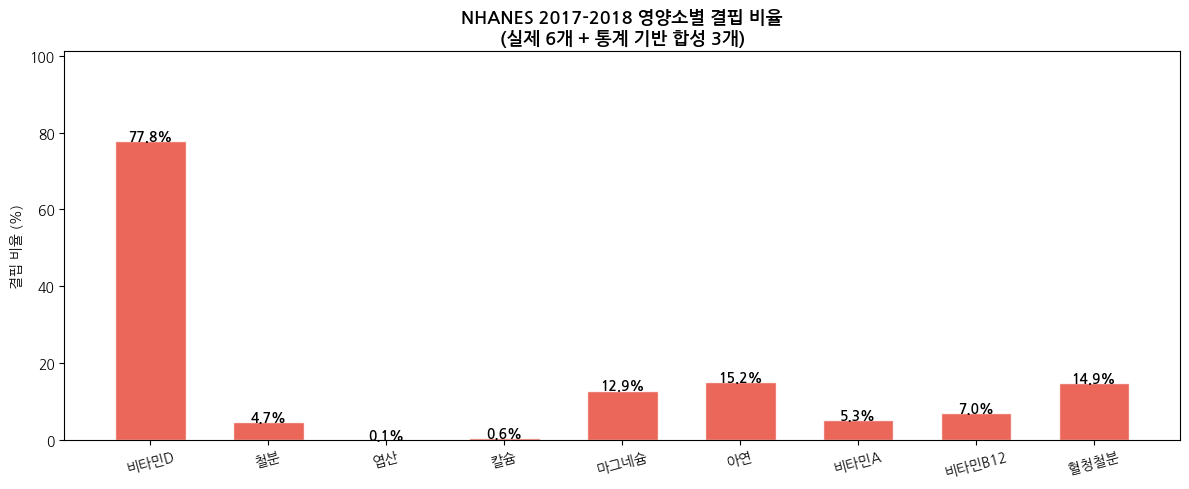

총 타겟 수: 9개


In [ ]:
# ── 셀 3: 결핍 비율 막대그래프 ──

# 영양소 한국어 이름 (그래프 라벨용)
label_names = {
    'label_vitD'  : '비타민D',
    'label_iron'  : '철분',
    'label_folate': '엽산',
    'label_ca'    : '칼슘',
    'label_mg'    : '마그네슘',
    'label_zinc'  : '아연',
    'label_vitA'  : '비타민A',
    'label_b12'   : '비타민B12',
    'label_sfe'   : '혈청철분',
}

ratios = [df[col].mean() * 100 for col in TARGET_COLS]  # 결핍 비율
names  = [label_names.get(col, col) for col in TARGET_COLS]  # 한국어 이름

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(names, ratios, color='#e74c3c', alpha=0.85, edgecolor='white', width=0.6)

# 막대 위에 수치 표시
for bar, ratio in zip(bars, ratios):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{ratio:.1f}%', ha='center', fontsize=10, fontweight='bold')

ax.set_title('NHANES 2017-2018 영양소별 결핍 비율\n(실제 6개 + 통계 기반 합성 3개)', fontsize=13, fontweight='bold')
ax.set_ylabel('결핍 비율 (%)')
ax.set_ylim(0, max(ratios) * 1.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
print(f'총 타겟 수: {len(TARGET_COLS)}개')

In [ ]:
# ==========================================
# ── 셀 4 & 5 통합: 데이터 전처리 및 누수 차단 파이프라인 ──
# ==========================================

# 사용할 피처 및 타겟 변수 정의
NUTRIENT_COLS = ['LBXVD2MS', 'LBXFERR', 'LBXRBF', 'LBXSCA',
                 'LBXSMG', 'LBXSZN', 'LBXVTC', 'LBDB12SI', 'LBXSFE']
EXTRA_COLS    = ['RIDAGEYR', 'RIAGENDR']  # 인구통계학 변수 (나이, 성별)

# 실제 데이터프레임에 존재하는 컬럼만 필터링하여 피처로 사용
FEATURE_COLS = [c for c in NUTRIENT_COLS + EXTRA_COLS if c in df.columns]

print('사용 피처:', FEATURE_COLS)
print('타겟 라벨:', TARGET_COLS)


# 피처(X) 및 타겟(y) 분리 후 유효 행 추출
X = df[FEATURE_COLS].copy()
y = df[TARGET_COLS].copy()

# 결측치가 없는 유효한 타겟 행만 마스킹하여 선택
valid_mask = y.notna().all(axis=1)
X = X[valid_mask]
y = y[valid_mask]

print(f'\n유효 샘플 수: {len(X)}개')


# 데이터 분할 (Train 70% / Val 15% / Test 15%)
# [데이터 누수 방지] 전처리 적용 전, 순수 원본 상태에서 격리 분할을 먼저 수행
# 1차 분할: Train(70%)과 임시 데이터(30%) 분리 (stratify로 첫 타겟의 결핍 비율 유지)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X.values, y.values, test_size=0.3, random_state=42,
    stratify=y[TARGET_COLS[0]]
)
# 2차 분할: 임시 데이터(30%)를 검증(15%)과 테스트(15%)로 균등 분할
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.5, random_state=42
)

print(f'Train 원본: {X_train_raw.shape[0]}개')
print(f'Val   원본: {X_val_raw.shape[0]}개')
print(f'Test  원본: {X_test_raw.shape[0]}개')


# 전처리 객체 독립 선언
imputer = KNNImputer(n_neighbors=5)  # KNN 기반 결측치 보완기
scaler = StandardScaler()             # Z-점수 정규화 스케일러


# 훈련 세트(Train Set) 기반 학습 및 전처리 적용
# [데이터 누수 방지] 오직 Train 데이터만을 기준으로 전처리 규칙을 학습(fit)함
X_train_imputed = imputer.fit_transform(X_train_raw)  # 결측치 보완 학습 및 적용
X_train = scaler.fit_transform(X_train_imputed)       # 정규화 스케일 학습 및 적용


# 검증 및 테스트 세트 전처리 적용
# [데이터 누수 방지] 미래 데이터(Val, Test)는 fit하지 않고, Train의 기준을 대입(transform)만 함
X_val_imputed = imputer.transform(X_val_raw)
X_val = scaler.transform(X_val_imputed)

X_test_imputed = imputer.transform(X_test_raw)
X_test = scaler.transform(X_test_imputed)

print(f'\nNaN 확인 (0이어야 함): Train={np.isnan(X_train).sum()}개, Val={np.isnan(X_val).sum()}개, Test={np.isnan(X_test).sum()}개')
print("✅ 데이터 누수 없이 완벽하게 데이터 격리 및 전처리 완료!")


# 클래스 불균형 해결을 위한 가중치 계산
# 각 영양소별 결핍/정상 비율에 반비례하도록 샘플별 페널티 가중치 누적
sample_weights = np.ones(len(y_train))  # 가중치 1로 기본 초기화

for i in range(y_train.shape[1]):
    col_vals = y_train[:, i]
    classes  = np.unique(col_vals)
    if len(classes) < 2:
        continue  # 단일 클래스만 존재할 경우 스킵

    # 'balanced' 옵션으로 클래스 비율에 따른 반비례 가중치 계산
    weights    = compute_class_weight('balanced', classes=classes, y=col_vals)
    weight_map = dict(zip(classes, weights))
    sample_weights += np.vectorize(weight_map.get)(col_vals)  # 가중치 합산

sample_weights /= (y_train.shape[1] + 1)  # 전체 타겟 수로 나누어 평균 가중치 산출
print(f'가중치 범위: {sample_weights.min():.3f} ~ {sample_weights.max():.3f}')

사용 피처: ['LBXVD2MS', 'LBXFERR', 'LBXRBF', 'LBXSCA', 'LBXSMG', 'LBXSZN', 'LBXVTC', 'LBDB12SI', 'LBXSFE', 'RIDAGEYR', 'RIAGENDR']
타겟 라벨: ['label_vitD', 'label_iron', 'label_folate', 'label_ca', 'label_mg', 'label_zinc', 'label_vitA', 'label_b12', 'label_sfe']

유효 샘플 수: 9254개
Train 원본: 6477개
Val   원본: 1388개
Test  원본: 1389개

NaN 확인 (0이어야 함): Train=0개, Val=0개, Test=0개
✅ 데이터 누수 없이 완벽하게 데이터 격리 및 전처리 완료!
가중치 범위: 0.600 ~ 55.112


In [ ]:
# ── 셀 6: DNN 모델 정의 ──

def build_model(input_dim, output_dim):
    model = Sequential([
        # 입력층: 128뉴런 / BatchNorm: 학습 안정화 / Dropout: 과적합 방지
        Dense(128, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.4),

        # 은닉층 1: 64뉴런
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        # 은닉층 2: 32뉴런
        Dense(32, activation='relu'),
        Dropout(0.2),

        # 출력층: sigmoid → 각 영양소 독립적으로 0~1 확률 출력
        # softmax는 합이 1이 되어 멀티라벨에 부적합, sigmoid 사용
        Dense(output_dim, activation='sigmoid')
    ])
    model.compile(
        optimizer=Adam(learning_rate=5e-4),   # Adam 옵티마이저
        loss='binary_crossentropy',            # 멀티라벨 표준 손실함수
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
    )
    return model

# 피처 수와 타겟 수 자동 반영
model = build_model(
    input_dim=X_train.shape[1],
    output_dim=len(TARGET_COLS)
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,937 (50.54 KB)

 Trainable params: 12,553 (49.04 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ── 셀 7: 모델 학습 ──

callbacks = [
    # val_auc가 20 epoch 동안 안 오르면 자동 중단 + 최적 가중치 복원
    EarlyStopping(monitor='val_auc', patience=20,
                  restore_best_weights=True, mode='max'),
    # val_loss 10 epoch 정체 시 학습률 절반으로 감소
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),  # 검증셋으로 과적합 모니터링
    epochs=150,                       # 최대 학습 횟수
    batch_size=64,                    # 한 번에 64개 샘플 학습
    sample_weight=sample_weights,     # 결핍 샘플 가중치 적용
    callbacks=callbacks,
    verbose=1
)


Epoch 1/150
102/102 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.2395 - auc: 0.5855 - loss: 0.7208 - val_accuracy: 0.9027 - val_auc: 0.7292 - val_loss: 0.5395 - learning_rate: 5.0000e-04
Epoch 2/150
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5797 - auc: 0.6632 - loss: 0.4903 - val_accuracy: 0.9107 - val_auc: 0.7736 - val_loss: 0.3740 - learning_rate: 5.0000e-04
Epoch 3/150
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7646 - auc: 0.6921 - loss: 0.3907 - val_accuracy: 0.9063 - val_auc: 0.8197 - val_loss: 0.2769 - learning_rate: 5.0000e-04
Epoch 4/150
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8067 - auc: 0.7722 - loss: 0.3386 - val_accuracy: 0.8934 - val_auc: 0.8548 - val_loss: 0.2264 - learning_rate: 5.0000e-04
Epoch 5/150
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8224 - auc: 0.7766 - loss: 0.3153 - val_accuracy: 0.8862 - val_auc: 0.8803 - val_loss: 0.1995 - learning_rate: 5.0000e-04
Epoch 6/150
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step 

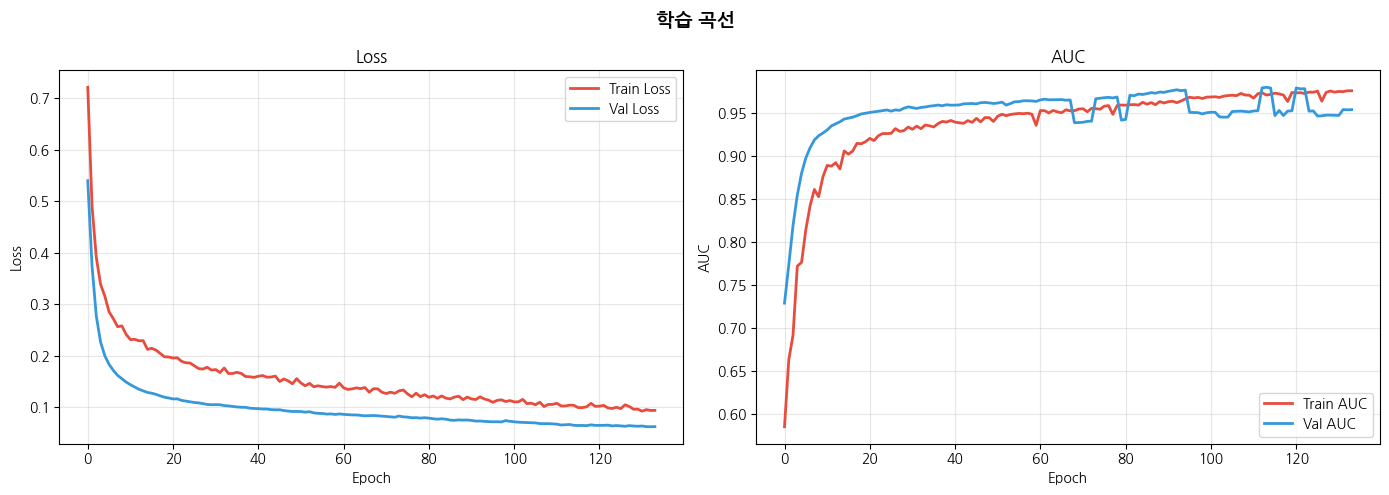

최종 Val AUC : 0.9802
최종 Val Loss: 0.0617
총 학습 Epoch: 134번


In [ ]:
# ── 셀 8: 학습 곡선 시각화 ──

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss: 낮을수록 좋음 / Train-Val 간격 크면 과적합
axes[0].plot(history.history['loss'],     label='Train Loss', color='#e74c3c', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='#3498db', linewidth=2)
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# AUC: 높을수록 좋음 / 0.5=랜덤, 1.0=완벽
axes[1].plot(history.history['auc'],     label='Train AUC', color='#e74c3c', linewidth=2)
axes[1].plot(history.history['val_auc'], label='Val AUC',   color='#3498db', linewidth=2)
axes[1].set_title('AUC')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('학습 곡선', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'최종 Val AUC : {max(history.history["val_auc"]):.4f}')
print(f'최종 Val Loss: {min(history.history["val_loss"]):.4f}')
print(f'총 학습 Epoch: {len(history.history["loss"])}번')

In [ ]:
# ── 셀 9: 테스트셋 평가 ──

# 테스트셋 예측 (0~1 확률)
y_pred_prob = model.predict(X_test)
# 임계값 0.5 기준으로 0/1 변환
y_pred = (y_pred_prob > 0.5).astype(int)

print('=' * 50)
print('📊 테스트셋 최종 평가 결과')
print('=' * 50)

# Hamming Loss: 전체 라벨 중 틀린 비율 (낮을수록 좋음)
print(f'Hamming Loss: {hamming_loss(y_test, y_pred):.4f}')

# Macro F1: 각 영양소 F1 평균 (불균형 데이터에 적합)
print(f'Macro F1    : {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}')

# 영양소별 상세 F1
print('\n--- 영양소별 F1 ---')
for i, col in enumerate(TARGET_COLS):
    name  = label_names.get(col, col)
    f1    = f1_score(y_test[:, i], y_pred[:, i], zero_division=0)
    n_def = int(y_test[:, i].sum())
    print(f'  {name:8s}: F1 = {f1:.3f}  (실제 결핍 {n_def}명)')

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
📊 테스트셋 최종 평가 결과
Hamming Loss: 0.0303
Macro F1    : 0.7488

--- 영양소별 F1 ---
  비타민D    : F1 = 0.884  (실제 결핍 1076명)
  철분      : F1 = 0.784  (실제 결핍 65명)
  엽산      : F1 = 0.000  (실제 결핍 1명)
  칼슘      : F1 = 0.375  (실제 결핍 4명)
  마그네슘    : F1 = 0.969  (실제 결핍 147명)
  아연      : F1 = 0.965  (실제 결핍 177명)
  비타민A    : F1 = 0.905  (실제 결핍 74명)
  비타민B12  : F1 = 0.944  (실제 결핍 85명)
  혈청철분    : F1 = 0.912  (실제 결핍 204명)


In [ ]:
# ── 셀 10: 최적 임계값 탐색 ──
# 임계값 0.5가 항상 최적이 아님
# 결핍 비율이 낮으면 임계값을 낮춰야 결핍을 더 잘 잡음

best_f1, best_threshold = 0, 0.5
for t in np.arange(0.2, 0.75, 0.05):  # 0.2~0.7 범위 탐색
    pred = (y_pred_prob > t).astype(int)
    f1   = f1_score(y_test, pred, average='macro', zero_division=0)
    if f1 > best_f1:
        best_f1, best_threshold = f1, t

print(f'최적 임계값: {best_threshold:.2f}  →  Macro F1: {best_f1:.4f}')
y_pred_best = (y_pred_prob > best_threshold).astype(int)

최적 임계값: 0.55  →  Macro F1: 0.7521


In [ ]:
# ── 셀 11: 추론 함수 ──
# 혈액 수치 입력 → 영양소 결핍 예측

def predict_deficiency(blood_values: dict):
    """
    혈액 수치를 딕셔너리로 입력하면 영양소 결핍 여부를 예측합니다.
    모르는 값은 None으로 입력하면 자동 보완됩니다.

    예시)
    predict_deficiency({
        'LBXVD2MS': 15.0,   # 비타민D
        'LBXFERR' : None,   # 모르면 None
        'RIDAGEYR': 25,     # 나이
        'RIAGENDR': 1,      # 성별 (1=남, 2=여)
    })
    """
    # 입력값을 데이터프레임으로 변환
    input_df = pd.DataFrame([blood_values], columns=FEATURE_COLS)
    # 학습 때와 동일한 imputer로 결측치 보완
    X_input  = imputer.transform(input_df)
    # 학습 때와 동일한 scaler로 정규화
    X_input  = scaler.transform(X_input)
    # 확률 예측
    prob     = model.predict(X_input, verbose=0)[0]
    # 최적 임계값으로 결핍 판정
    pred     = (prob > best_threshold).astype(int)

    print('=' * 42)
    print('🩸 영양소 결핍 예측 결과')
    print('=' * 42)
    for label, p, flag in zip(TARGET_COLS, prob, pred):
        name   = label_names.get(label, label)
        status = '⚠️  결핍 의심' if flag else '✅ 정상'
        print(f'{name:8s}: {status}  (확률: {p:.1%})')

# 테스트셋 첫 번째 샘플로 동작 확인
sample = {col: float(X_test[0][i]) for i, col in enumerate(FEATURE_COLS)}
predict_deficiency(sample)

🩸 영양소 결핍 예측 결과
비타민D    : ⚠️  결핍 의심  (확률: 100.0%)
철분      : ✅ 정상  (확률: 0.0%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ⚠️  결핍 의심  (확률: 100.0%)
마그네슘    : ⚠️  결핍 의심  (확률: 99.4%)
아연      : ⚠️  결핍 의심  (확률: 100.0%)
비타민A    : ✅ 정상  (확률: 0.0%)
비타민B12  : ⚠️  결핍 의심  (확률: 80.6%)
혈청철분    : ⚠️  결핍 의심  (확률: 100.0%)


In [ ]:
# ── 셀 12: 모델 저장 ──
import joblib

model.save('nutrient_model.h5')            # DNN 모델 저장
joblib.dump(imputer,      'imputer.pkl')   # 결측치 처리기 저장
joblib.dump(scaler,       'scaler.pkl')    # 정규화 스케일러 저장
joblib.dump(TARGET_COLS,  'targets.pkl')   # 타겟 컬럼 목록 저장
joblib.dump(FEATURE_COLS, 'features.pkl') # 피처 컬럼 목록 저장

print('✅ 모델 저장 완료!')
print('  nutrient_model.h5  → DNN 모델')
print('  imputer.pkl        → 결측치 처리기')
print('  scaler.pkl         → 정규화 스케일러')
print('  targets.pkl        → 타겟 컬럼 목록')
print('  features.pkl       → 피처 컬럼 목록')

✅ 모델 저장 완료!
  nutrient_model.h5  → DNN 모델
  imputer.pkl        → 결측치 처리기
  scaler.pkl         → 정규화 스케일러
  targets.pkl        → 타겟 컬럼 목록
  features.pkl       → 피처 컬럼 목록


In [ ]:
#테스트 1 정상 남성 (30세)
predict_deficiency({
    'LBXVD2MS': 45.0,  'LBXFERR': 80.0,  'LBXRBF': 350.0,
    'LBXSCA' :  9.5,   'LBXSMG':   2.0,  'LBXSZN':  85.0,
    'LBXVTC' : 55.0,   'LBDB12SI': 500.0,'LBXSFE': 100.0,
    'RIDAGEYR': 30, 'RIAGENDR': 1
})

🩸 영양소 결핍 예측 결과
비타민D    : ✅ 정상  (확률: 15.1%)
철분      : ✅ 정상  (확률: 0.7%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 0.0%)
마그네슘    : ✅ 정상  (확률: 0.2%)
아연      : ✅ 정상  (확률: 0.0%)
비타민A    : ✅ 정상  (확률: 0.0%)
비타민B12  : ✅ 정상  (확률: 0.0%)
혈청철분    : ✅ 정상  (확률: 0.0%)


In [ ]:
#테스트2 비타민D 결핍 여성 (25세)
predict_deficiency({
    'LBXVD2MS': 11.0,  'LBXFERR': 25.0,  'LBXRBF': 280.0,
    'LBXSCA' :  9.3,   'LBXSMG':   1.9,  'LBXSZN':  78.0,
    'LBXVTC' : 48.0,   'LBDB12SI': 420.0,'LBXSFE':  90.0,
    'RIDAGEYR': 25, 'RIAGENDR': 2
})

🩸 영양소 결핍 예측 결과
비타민D    : ✅ 정상  (확률: 47.5%)
철분      : ✅ 정상  (확률: 0.5%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 0.0%)
마그네슘    : ✅ 정상  (확률: 0.1%)
아연      : ✅ 정상  (확률: 0.0%)
비타민A    : ✅ 정상  (확률: 0.0%)
비타민B12  : ✅ 정상  (확률: 0.0%)
혈청철분    : ✅ 정상  (확률: 0.0%)


In [ ]:
# 테스트 3: 철분 결핍 여성 (22세)
predict_deficiency({
    'LBXVD2MS': 32.0,  'LBXFERR':  6.0,  'LBXRBF': 260.0,
    'LBXSCA' :  9.1,   'LBXSMG':  1.85,  'LBXSZN':  72.0,
    'LBXVTC' : 42.0,   'LBDB12SI': 380.0,'LBXSFE':  42.0,
    'RIDAGEYR': 22, 'RIAGENDR': 2
})

🩸 영양소 결핍 예측 결과
비타민D    : ⚠️  결핍 의심  (확률: 79.4%)
철분      : ⚠️  결핍 의심  (확률: 89.2%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 0.2%)
마그네슘    : ✅ 정상  (확률: 0.4%)
아연      : ✅ 정상  (확률: 1.1%)
비타민A    : ✅ 정상  (확률: 0.1%)
비타민B12  : ✅ 정상  (확률: 0.1%)
혈청철분    : ⚠️  결핍 의심  (확률: 80.0%)


In [ ]:
#테스트 4 : 복합 결핍 남성 (45세) ──
predict_deficiency({
    'LBXVD2MS': 14.0,  'LBXFERR': 18.0,  'LBXRBF': 110.0,
    'LBXSCA' :  9.0,   'LBXSMG':  1.75,  'LBXSZN':  58.0,
    'LBXVTC' : 35.0,   'LBDB12SI': 320.0,'LBXSFE':  70.0,
    'RIDAGEYR': 45, 'RIAGENDR': 1
})

🩸 영양소 결핍 예측 결과
비타민D    : ⚠️  결핍 의심  (확률: 87.9%)
철분      : ✅ 정상  (확률: 50.7%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 1.0%)
마그네슘    : ✅ 정상  (확률: 0.6%)
아연      : ⚠️  결핍 의심  (확률: 100.0%)
비타민A    : ✅ 정상  (확률: 1.5%)
비타민B12  : ✅ 정상  (확률: 1.0%)
혈청철분    : ✅ 정상  (확률: 16.1%)


In [ ]:
# ── 케이스 5: 고령 여성 (65세) ──
predict_deficiency({
    'LBXVD2MS': 16.0,  'LBXFERR': 30.0,  'LBXRBF': 200.0,
    'LBXSCA' :  8.8,   'LBXSMG':   1.8,  'LBXSZN':  75.0,
    'LBXVTC' : 40.0,   'LBDB12SI': 160.0,'LBXSFE':  80.0,
    'RIDAGEYR': 65, 'RIAGENDR': 2
})

🩸 영양소 결핍 예측 결과
비타민D    : ⚠️  결핍 의심  (확률: 86.7%)
철분      : ✅ 정상  (확률: 1.1%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 0.4%)
마그네슘    : ✅ 정상  (확률: 1.0%)
아연      : ✅ 정상  (확률: 0.5%)
비타민A    : ✅ 정상  (확률: 0.4%)
비타민B12  : ⚠️  결핍 의심  (확률: 98.8%)
혈청철분    : ✅ 정상  (확률: 0.2%)


In [ ]:
# ── 케이스 6: 아연 결핍 남성 (28세) ──
predict_deficiency({
    'LBXVD2MS': 38.0,  'LBXFERR': 95.0,  'LBXRBF': 310.0,
    'LBXSCA' :  9.4,   'LBXSMG':   2.1,  'LBXSZN':  52.0,
    'LBXVTC' : 50.0,   'LBDB12SI': 450.0,'LBXSFE':  95.0,
    'RIDAGEYR': 28, 'RIAGENDR': 1
})

🩸 영양소 결핍 예측 결과
비타민D    : ✅ 정상  (확률: 26.0%)
철분      : ✅ 정상  (확률: 2.6%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 0.0%)
마그네슘    : ✅ 정상  (확률: 0.1%)
아연      : ⚠️  결핍 의심  (확률: 100.0%)
비타민A    : ✅ 정상  (확률: 0.1%)
비타민B12  : ✅ 정상  (확률: 0.0%)
혈청철분    : ✅ 정상  (확률: 0.1%)


In [ ]:
# ── 케이스 7: 칼슘+마그네슘 결핍 여성 (35세) ──
predict_deficiency({
    'LBXVD2MS': 25.0,  'LBXFERR': 18.0,  'LBXRBF': 190.0,
    'LBXSCA' :  7.9,   'LBXSMG':   1.5,  'LBXSZN':  80.0,
    'LBXVTC' : 45.0,   'LBDB12SI': 390.0,'LBXSFE':  88.0,
    'RIDAGEYR': 35, 'RIAGENDR': 2
})

🩸 영양소 결핍 예측 결과
비타민D    : ⚠️  결핍 의심  (확률: 98.3%)
철분      : ✅ 정상  (확률: 1.2%)
엽산      : ✅ 정상  (확률: 8.3%)
칼슘      : ⚠️  결핍 의심  (확률: 84.0%)
마그네슘    : ⚠️  결핍 의심  (확률: 96.0%)
아연      : ✅ 정상  (확률: 1.3%)
비타민A    : ✅ 정상  (확률: 0.0%)
비타민B12  : ✅ 정상  (확률: 0.8%)
혈청철분    : ✅ 정상  (확률: 1.6%)


In [ ]:
# ── 케이스 9: 경계선 수치 여성 (32세) ──
# 모든 수치가 기준치 바로 근처 → 모델이 확률로 판단하는 케이스
predict_deficiency({
    'LBXVD2MS': 21.0,  'LBXFERR': 12.0,  'LBXRBF': 145.0,
    'LBXSCA' :  8.6,   'LBXSMG':  1.72,  'LBXSZN':  71.0,
    'LBXVTC' : 32.0,   'LBDB12SI': 210.0,'LBXSFE':  63.0,
    'RIDAGEYR': 32, 'RIAGENDR': 2
})

🩸 영양소 결핍 예측 결과
비타민D    : ⚠️  결핍 의심  (확률: 87.0%)
철분      : ⚠️  결핍 의심  (확률: 56.1%)
엽산      : ✅ 정상  (확률: 2.1%)
칼슘      : ✅ 정상  (확률: 47.1%)
마그네슘    : ✅ 정상  (확률: 6.3%)
아연      : ✅ 정상  (확률: 25.7%)
비타민A    : ✅ 정상  (확률: 2.4%)
비타민B12  : ⚠️  결핍 의심  (확률: 70.7%)
혈청철분    : ✅ 정상  (확률: 49.9%)


In [ ]:
# ── 케이스 10: 혈청 철분 결핍 남성 (27세) ──
predict_deficiency({
    'LBXVD2MS': 42.0,  'LBXFERR': 28.0,  'LBXRBF': 290.0,
    'LBXSCA' :  9.2,   'LBXSMG':  1.95,  'LBXSZN':  82.0,
    'LBXVTC' : 52.0,   'LBDB12SI': 480.0,'LBXSFE':  42.0,
    'RIDAGEYR': 27, 'RIAGENDR': 1
})

🩸 영양소 결핍 예측 결과
비타민D    : ✅ 정상  (확률: 22.1%)
철분      : ✅ 정상  (확률: 35.7%)
엽산      : ✅ 정상  (확률: 0.0%)
칼슘      : ✅ 정상  (확률: 0.0%)
마그네슘    : ✅ 정상  (확률: 0.3%)
아연      : ✅ 정상  (확률: 0.1%)
비타민A    : ✅ 정상  (확률: 0.1%)
비타민B12  : ✅ 정상  (확률: 0.1%)
혈청철분    : ⚠️  결핍 의심  (확률: 74.2%)
